# Exploratory Data Analysis

This notebook answers four questions before modeling: how skewed are the paired resource measurements, how often does each version use less energy, how do resource changes relate to one another, and which engineered features or fitted-model importance rankings deserve investigation? The overall project predicts which of two implementations for the same problem uses less energy from static code features; this notebook describes the benchmark and does not train that predictor. All distributions are shown on a log scale where needed; energy and runtime differences are oriented as **V0 minus V1** (positive means V1 used less).

Run Notebook 01 first. The engineered-feature and model-importance sections are optional until Notebooks 03 and 04 have produced their artifacts. Feature importance here is descriptive only; it is not a license to select features using the held-out folds.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents) if (path / "Data" / "Processed").is_dir()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Run 01_data_understanding.ipynb first to create Data/Processed.")
PROCESSED_DIR = ROOT / "Data" / "Processed"
RESULTS_DIR = ROOT / "Results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

required_data = [
    PROCESSED_DIR / "validated_energy_results.parquet",
    PROCESSED_DIR / "significant_energy_diff.parquet",
    PROCESSED_DIR / "classified_smells.parquet",
]
missing_data = [str(path) for path in required_data if not path.is_file()]
if missing_data:
    raise FileNotFoundError(f"Required Notebook 01 outputs are missing: {missing_data}")

df_full = pd.read_parquet(required_data[0])
df_significant = pd.read_parquet(required_data[1])
df_classified = pd.read_parquet(required_data[2])

metric_columns = {
    "Energy (J)": ("result_energy_v0", "result_energy_v1"),
    "Runtime (s)": ("result_time_v0", "result_time_v1"),
    "Memory (KB)": ("result_memory_v0", "result_memory_v1"),
}
for label, (column_v0, column_v1) in metric_columns.items():
    missing = sorted({column_v0, column_v1} - set(df_full.columns))
    if missing:
        raise ValueError(f"Validated results are missing {label} columns: {missing}")
    df_full[f"{label}_difference_v0_minus_v1"] = df_full[column_v0] - df_full[column_v1]

df_full["energy_tie"] = df_full["result_energy_v0"].eq(df_full["result_energy_v1"])
df_full["energy_winner"] = np.select(
    [df_full["result_energy_v1"] < df_full["result_energy_v0"], df_full["energy_tie"]],
    [1, -1],
    default=0,
)

sns.set_theme(style="whitegrid", context="notebook")
print(
    f"Validated: {len(df_full):,} pairs across {df_full['problem_id'].nunique():,} problems; "
    f"significant subset: {len(df_significant):,} pairs across "
    f"{df_significant['problem_id'].nunique():,} problems."
)

Validated: 21,428 pairs across 1,232 problems; significant subset: 3,000 pairs across 476 problems.


## 1. Dataset and paired-outcome summary

Use medians and percentiles alongside means: a few large measurements can pull resource means far from a typical pair. The winner percentages include ties as a separate outcome.

In [2]:
summary_rows = []
for label, (column_v0, column_v1) in metric_columns.items():
    v0, v1 = df_full[column_v0], df_full[column_v1]
    difference = v0 - v1
    denominator = (v0 + v1) / 2
    relative_change = (100 * difference / denominator).where(denominator.ne(0))
    summary_rows.append({
        "metric": label,
        "V0 median": v0.median(),
        "V1 median": v1.median(),
        "V0 mean": v0.mean(),
        "V1 mean": v1.mean(),
        "V0-minus-V1 median": difference.median(),
        "V0-minus-V1 p05": difference.quantile(0.05),
        "V0-minus-V1 p95": difference.quantile(0.95),
        "V1 lower": int((v1 < v0).sum()),
        "V0 lower": int((v0 < v1).sum()),
        "ties": int(v0.eq(v1).sum()),
        "median relative change (%)": relative_change.median(),
    })
comparison_summary = pd.DataFrame(summary_rows)
comparison_summary.to_csv(RESULTS_DIR / "comparison_summary.csv", index=False)
display(comparison_summary.round(3))

outcome_summary = pd.DataFrame({
    "outcome": ["V1 uses less energy", "V0 uses less energy", "Tie"],
    "pairs": [int((df_full["energy_winner"] == 1).sum()), int((df_full["energy_winner"] == 0).sum()), int((df_full["energy_winner"] == -1).sum())],
})
outcome_summary["share (%)"] = 100 * outcome_summary["pairs"] / len(df_full)
outcome_summary.to_csv(RESULTS_DIR / "energy_outcome_summary.csv", index=False)
display(outcome_summary.round(2))

category_counts = {}
if "final_classification" in df_classified.columns:
    for value in df_classified["final_classification"].dropna():
        parsed = json.loads(value) if isinstance(value, str) else value
        entries = parsed if isinstance(parsed, list) else [parsed]
        for entry in entries:
            if isinstance(entry, dict) and entry.get("category_id"):
                category = str(entry["category_id"])
                category_counts[category] = category_counts.get(category, 0) + 1
classification_summary = pd.DataFrame(
    sorted(category_counts.items(), key=lambda item: item[1], reverse=True),
    columns=["category_id", "count"],
)
classification_summary.to_csv(RESULTS_DIR / "classification_category_counts.csv", index=False)
if not classification_summary.empty:
    display(classification_summary.head(20))

,metric,V0 median,V1 median,V0 mean,V1 mean,V0-minus-V1 median,V0-minus-V1 p05,V0-minus-V1 p95,V1 lower,V0 lower,ties,median relative change (%)
0,Energy (J),358.090,357.190,836.525,639.513,0.970,-30.509,1358.579,12698,8712,18,0.271
1,Runtime (s),4.856,4.855,9.816,7.759,0.001,-0.275,16.238,12075,9353,0,0.013
2,Memory (KB),11228.000,11224.000,13673.072,12784.275,4.000,-232.000,1467.800,10856,10251,321,0.036


,outcome,pairs,share (%)
0,V1 uses less energy,12698,59.26
1,V0 uses less energy,8712,40.66
2,Tie,18,0.08


,category_id,count
0,C7,1287
1,C6,1194
2,C3,1030
3,C1,822
4,C10,601
5,C5,557
6,C8,123
7,C2,111
8,C4,88
9,C12,61


## 2. Compare paired resource distributions

Resource values are strongly right-skewed. Plotting `log10(value + 1)` keeps the long tail visible without deleting large observations. These are paired measurements, so the second figure also shows the distribution of within-pair changes.

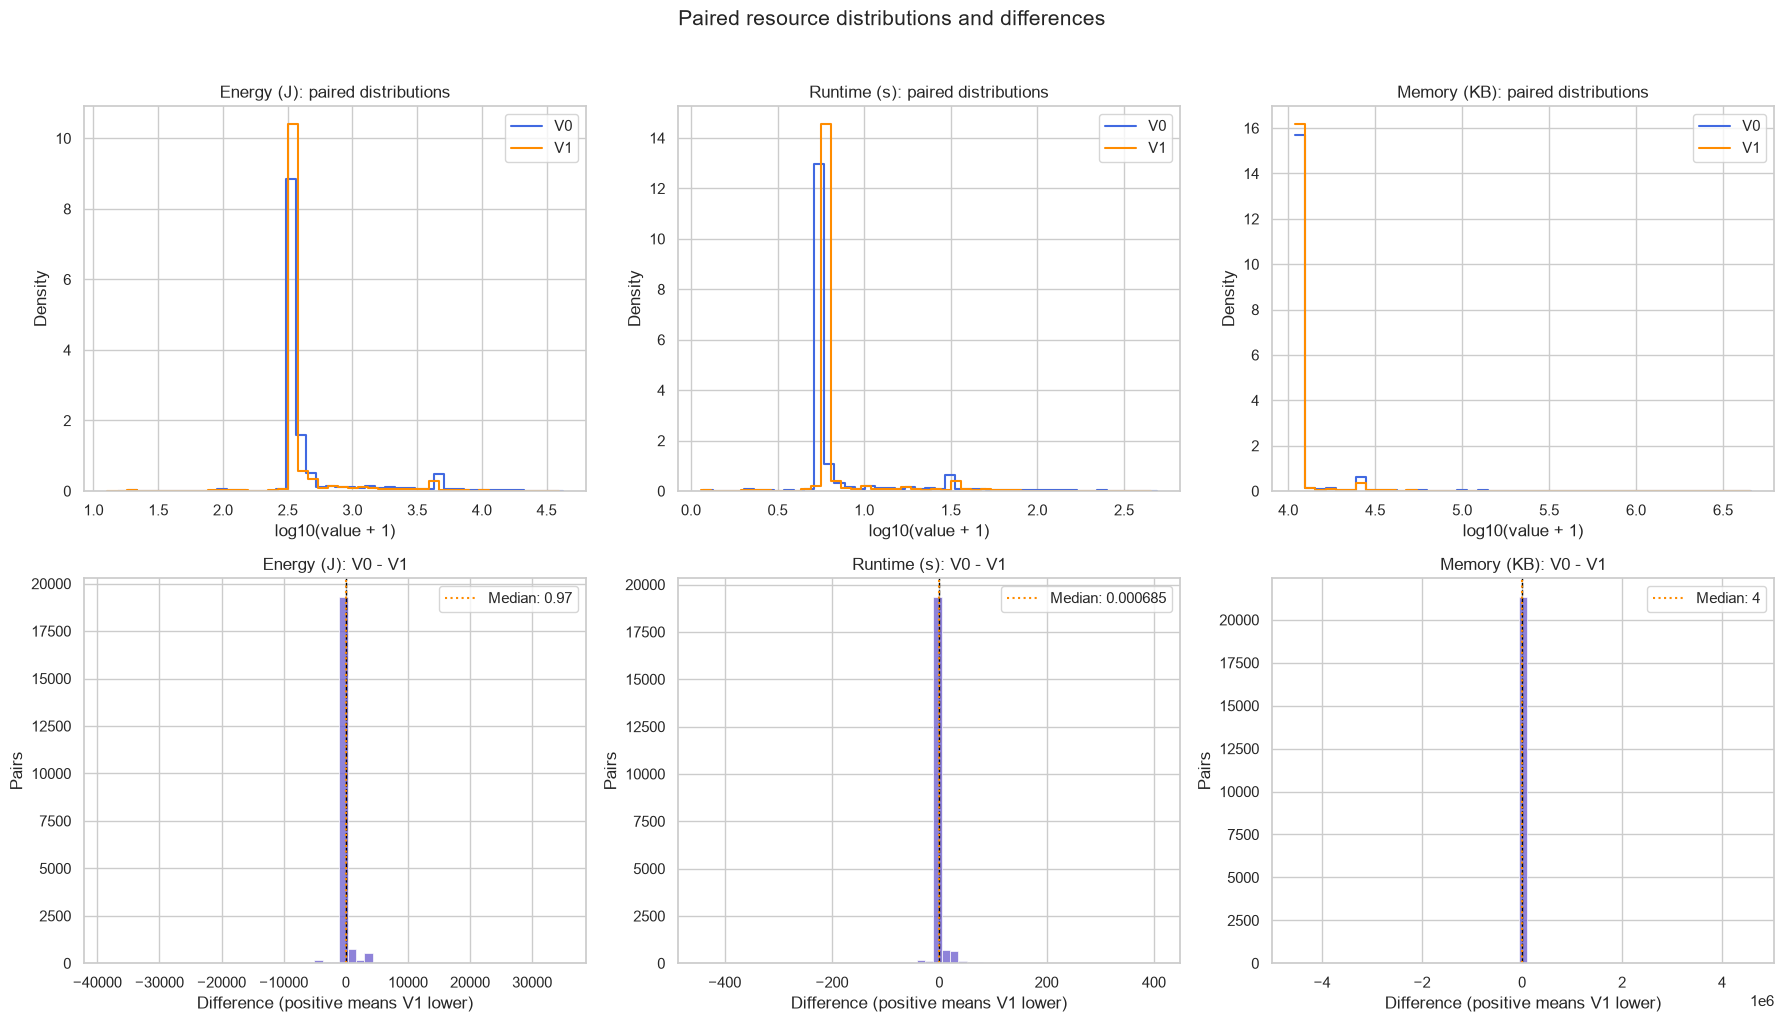

Energy relative-change percentiles (positive means V1 uses less):


,0.05,0.25,0.50,0.75,0.95
relative change (%),-5.74,-0.51,0.27,1.38,87.99


In [3]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for column_index, (label, (column_v0, column_v1)) in enumerate(metric_columns.items()):
    ax = axes[0, column_index]
    for column, version, color in [(column_v0, "V0", "royalblue"), (column_v1, "V1", "darkorange")]:
        values = df_full[column].dropna()
        sns.histplot(np.log10(values.clip(lower=0) + 1), bins=45, stat="density", element="step", fill=False, ax=ax, label=version, color=color)
    ax.set(title=f"{label}: paired distributions", xlabel="log10(value + 1)", ylabel="Density")
    ax.legend()

    delta_column = f"{label}_difference_v0_minus_v1"
    ax = axes[1, column_index]
    values = df_full[delta_column].dropna()
    sns.histplot(values, bins=55, ax=ax, color="slateblue")
    ax.axvline(0, color="black", linestyle="--", linewidth=1)
    ax.axvline(values.median(), color="darkorange", linestyle=":", linewidth=1.5, label=f"Median: {values.median():.3g}")
    ax.set(title=f"{label}: V0 - V1", xlabel="Difference (positive means V1 lower)", ylabel="Pairs")
    ax.legend()
fig.suptitle("Paired resource distributions and differences", y=1.02, fontsize=15)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "resource_distributions.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

energy_relative = 100 * (df_full["result_energy_v0"] - df_full["result_energy_v1"]) / ((df_full["result_energy_v0"] + df_full["result_energy_v1"]) / 2).replace(0, np.nan)
print("Energy relative-change percentiles (positive means V1 uses less):")
display(energy_relative.quantile([0.05, 0.25, 0.5, 0.75, 0.95]).rename("relative change (%)").to_frame().T.round(2))

## 3. Relationships and problem-level variation

These correlations are descriptive, not causal. Aggregating first by problem prevents frequently represented problems from dominating the problem-level summary.

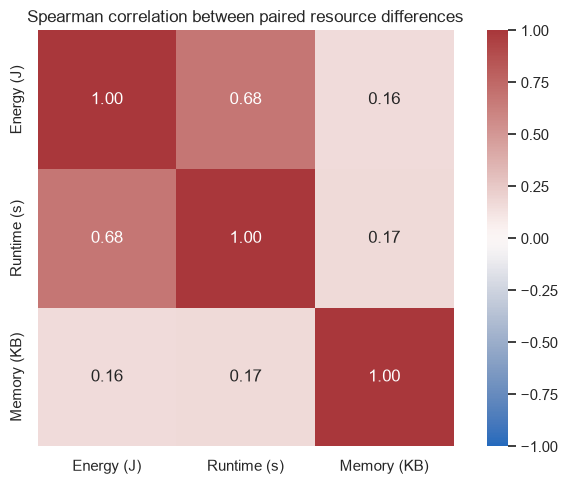

,Energy (J),Runtime (s),Memory (KB)
Energy (J),1.000,0.677,0.164
Runtime (s),0.677,1.000,0.166
Memory (KB),0.164,0.166,1.000


,problem_id,pairs,median_energy_difference_j,median_energy_relative_change_pct,share_v1_lower
804,p03160,268,0.615,0.173,0.560
491,p02713,193,500.220,25.483,0.746
498,p02720,188,2.325,0.640,0.654
806,p03162,176,-0.060,-0.017,0.489
1154,p03835,175,0.330,0.093,0.531
450,p02659,174,14.030,3.850,0.730
906,p03329,174,188.015,22.644,0.787
752,p03078,173,-1.070,-0.299,0.393
985,p03478,160,0.840,0.237,0.612
477,p02695,160,3.520,0.939,0.694


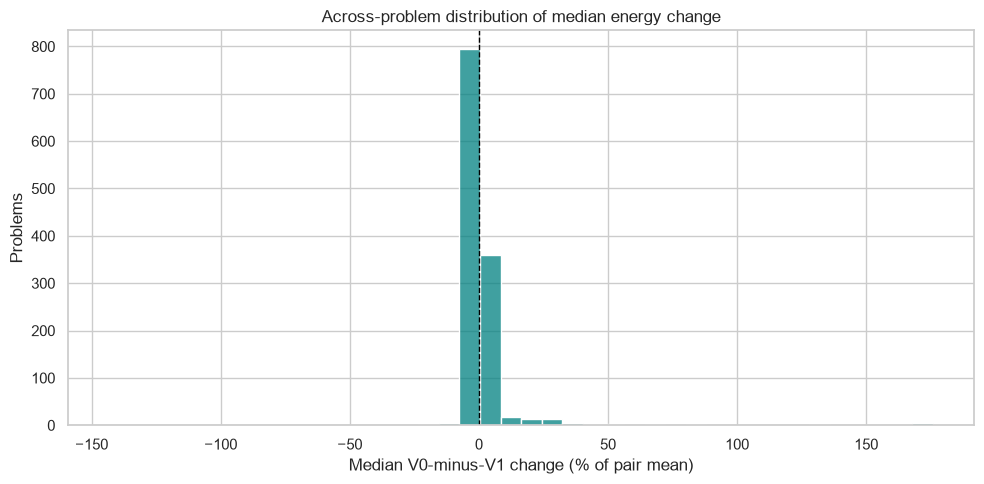

In [4]:
difference_columns = [f"{label}_difference_v0_minus_v1" for label in metric_columns]
difference_data = df_full[difference_columns].rename(columns={
    f"{label}_difference_v0_minus_v1": label for label in metric_columns
})
spearman_correlations = difference_data.corr(method="spearman")
spearman_correlations.to_csv(RESULTS_DIR / "resource_difference_spearman.csv")
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(spearman_correlations, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Spearman correlation between paired resource differences")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "resource_difference_correlations.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)
display(spearman_correlations.round(3))

problem_summary = (
    df_full.assign(
        energy_relative_change_pct=energy_relative,
        v1_uses_less_energy=df_full["energy_winner"].eq(1),
    )
    .groupby("problem_id", as_index=False)
    .agg(
        pairs=("energy_winner", "size"),
        median_energy_difference_j=("Energy (J)_difference_v0_minus_v1", "median"),
        median_energy_relative_change_pct=("energy_relative_change_pct", "median"),
        share_v1_lower=("v1_uses_less_energy", "mean"),
    )
)
problem_summary.to_csv(RESULTS_DIR / "problem_level_energy_summary.csv", index=False)
display(problem_summary.sort_values("pairs", ascending=False).head(15).round(3))
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(problem_summary["median_energy_relative_change_pct"].dropna(), bins=40, ax=ax, color="teal")
ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.set(title="Across-problem distribution of median energy change", xlabel="Median V0-minus-V1 change (% of pair mean)", ylabel="Problems")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "problem_level_energy_changes.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

## 4. Engineered-feature audit and importance stability

Run Notebook 03 to create the prepared datasets. This section reports variation and correlation; **it does not drop zero-variance or other features**. If Notebook 04 has been run, it also compares fitted-model importance ranks across both datasets. Importance magnitudes differ between model families, so features are compared by their within-model rank. The bottom-20% cutoff is only a way to identify candidates for a later fold-safe ablation experiment.

,dataset,feature_config,features,zero_variance_features,median_variance
0,significant,combined,45,0,4.026181
1,significant,differences,15,0,3.241872
2,significant,per_version,30,0,4.620925
3,validated,combined,45,0,3.695456
4,validated,differences,15,0,1.626324
5,validated,per_version,30,0,3.984394


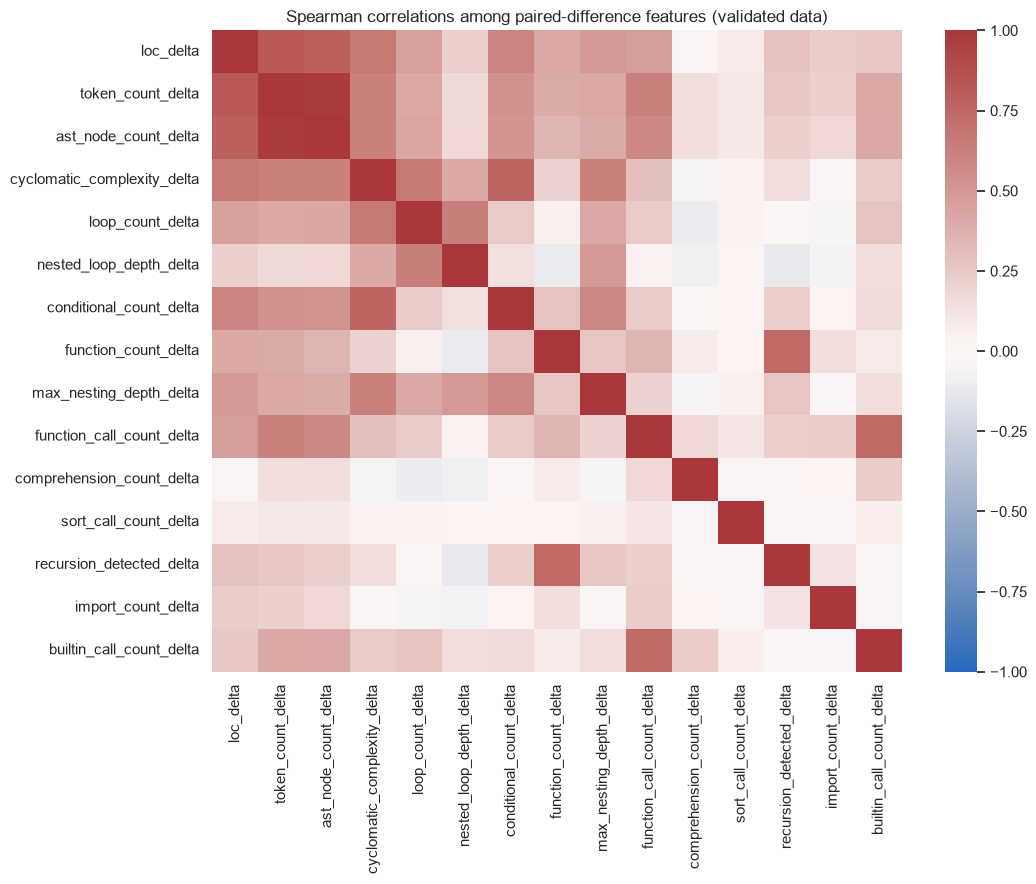

Features most frequently ranked in the bottom 20% (separately per dataset/model):


,feature_config,feature,bottom_20_runs,evaluated_runs,mean_rank_percentile,bottom_20_share
40,combined,sort_call_count_v0,4,6,0.181481,0.666667
37,combined,recursion_detected_v0,4,6,0.322222,0.666667
36,combined,recursion_detected_delta,4,6,0.366667,0.666667
7,combined,comprehension_count_v0,3,6,0.248148,0.500000
19,combined,function_count_v0,3,6,0.266667,0.500000
35,combined,nested_loop_depth_v1,3,6,0.318519,0.500000
39,combined,sort_call_count_delta,3,6,0.318519,0.500000
41,combined,sort_call_count_v1,3,6,0.318519,0.500000
67,config_A,nested_loop_depth_v0,4,6,0.305556,0.666667
71,config_A,sort_call_count_v0,3,6,0.350000,0.500000


config_A: bottom-20% intersection across 6 dataset/model fits: none
config_B: bottom-20% intersection across 6 dataset/model fits: none
combined: bottom-20% intersection across 6 dataset/model fits: none


In [5]:
prepared_paths = {
    "validated": PROCESSED_DIR / "prepared_training_dataset.parquet",
    "significant": PROCESSED_DIR / "prepared_significant_training_dataset.parquet",
}
manifest_path = PROCESSED_DIR / "feature_manifest.json"
feature_frames = {}
if manifest_path.is_file() and all(path.is_file() for path in prepared_paths.values()):
    feature_manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
    feature_frames = {name: pd.read_parquet(path) for name, path in prepared_paths.items()}
    variance_rows = []
    for dataset_name, frame in feature_frames.items():
        for config_name, columns in feature_manifest["configurations"].items():
            counts = frame[columns].nunique(dropna=False)
            variances = frame[columns].var(ddof=0)
            for column in columns:
                variance_rows.append({
                    "dataset": dataset_name,
                    "feature_config": config_name,
                    "feature": column,
                    "unique_values": int(counts[column]),
                    "variance": float(variances[column]),
                    "zero_variance": bool(counts[column] <= 1),
                })
    feature_variance = pd.DataFrame(variance_rows)
    feature_variance.to_csv(RESULTS_DIR / "feature_variance_eda.csv", index=False)
    display(
        feature_variance.groupby(["dataset", "feature_config"], as_index=False)
        .agg(features=("feature", "size"), zero_variance_features=("zero_variance", "sum"), median_variance=("variance", "median"))
    )

    if "differences" in feature_manifest["configurations"]:
        delta_features = feature_manifest["configurations"]["differences"]
        delta_correlations = feature_frames["validated"][delta_features].corr(method="spearman")
        fig, ax = plt.subplots(figsize=(11, 9))
        sns.heatmap(delta_correlations, cmap="vlag", center=0, vmin=-1, vmax=1, ax=ax)
        ax.set_title("Spearman correlations among paired-difference features (validated data)")
        fig.tight_layout()
        fig.savefig(RESULTS_DIR / "difference_feature_correlations.png", dpi=160, bbox_inches="tight")
        plt.show()
        plt.close(fig)
else:
    print("Prepared feature datasets not found; run Notebook 03 to enable the engineered-feature audit.")

importance_rows = []
if feature_frames:
    import joblib

    for dataset_name in feature_frames:
        for config_name in ("config_A", "config_B", "combined"):
            model_dir = PROCESSED_DIR / "models" / dataset_name / config_name
            metadata_path = model_dir / "training_metadata.json"
            if not metadata_path.is_file():
                continue
            metadata = json.loads(metadata_path.read_text(encoding="utf-8"))
            feature_names = metadata["feature_columns"]
            for model_name in ("logistic_regression", "random_forest", "xgboost"):
                model_path = model_dir / f"{model_name}.joblib"
                if not model_path.is_file():
                    continue
                estimator = joblib.load(model_path)
                if model_name == "logistic_regression":
                    raw_importance = np.abs(estimator[-1].coef_).mean(axis=0)
                else:
                    raw_importance = estimator.feature_importances_
                if len(raw_importance) != len(feature_names):
                    raise ValueError(f"Importance/feature count mismatch: {model_path}")
                importance_rank = pd.Series(raw_importance, index=feature_names).rank(method="average", pct=True)
                for feature, value in zip(feature_names, raw_importance):
                    importance_rows.append({
                        "dataset": dataset_name,
                        "feature_config": config_name,
                        "model": model_name,
                        "feature": feature,
                        "importance": float(value),
                        "rank_percentile": float(importance_rank[feature]),
                    })

if importance_rows:
    importance_all = pd.DataFrame(importance_rows)
    importance_all["bottom_20_percent"] = importance_all["rank_percentile"].le(0.20)
    importance_all.to_csv(RESULTS_DIR / "feature_importance_all_configs.csv", index=False)
    importance_frequency = (
        importance_all.groupby(["feature_config", "feature"], as_index=False)
        .agg(
            bottom_20_runs=("bottom_20_percent", "sum"),
            evaluated_runs=("model", "size"),
            mean_rank_percentile=("rank_percentile", "mean"),
        )
    )
    importance_frequency["bottom_20_share"] = importance_frequency["bottom_20_runs"] / importance_frequency["evaluated_runs"]
    importance_frequency.to_csv(RESULTS_DIR / "feature_importance_bottom_frequency.csv", index=False)
    print("Features most frequently ranked in the bottom 20% (separately per dataset/model):")
    display(
        importance_frequency.sort_values(["feature_config", "bottom_20_runs", "mean_rank_percentile"], ascending=[True, False, True])
        .groupby("feature_config", group_keys=False)
        .head(8)
    )
    for config_name in ("config_A", "config_B", "combined"):
        runs = importance_all.loc[importance_all["feature_config"].eq(config_name)]
        run_count = runs[["dataset", "model"]].drop_duplicates().shape[0]
        if run_count:
            bottom_sets = [
                set(group.loc[group["bottom_20_percent"], "feature"])
                for _, group in runs.groupby(["dataset", "model"])
            ]
            shared_bottom = set.intersection(*bottom_sets) if bottom_sets else set()
            print(f"{config_name}: bottom-20% intersection across {run_count} dataset/model fits: {sorted(shared_bottom) or 'none'}")
else:
    print("Fitted configuration models not found; run Notebook 04 to enable the importance-stability audit.")

In [8]:
import json
from pathlib import Path
import pandas  as pd

ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents) if (path / "Data" / "Processed").is_dir()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Run 01_data_understanding.ipynb first to create Data/Processed.")
PROCESSED_DIR = ROOT / "Data" / "Processed"

manifest_path = PROCESSED_DIR / "feature_manifest.json"
if not manifest_path.is_file():
    raise FileNotFoundError("Run Notebook 03 to create the feature manifest.")

manifest_configurations = json.loads(manifest_path.read_text(encoding="utf-8"))["configurations"]
for config_label, manifest_key in (("Config A", "per_version"), ("Config B", "differences")):
    features = manifest_configurations[manifest_key]
    print(f"{config_label} ({len(features)} features):")
    display(pd.DataFrame({"feature": features}))

Config A (30 features):


,feature
0,loc_v0
1,loc_v1
2,token_count_v0
3,token_count_v1
4,ast_node_count_v0
5,ast_node_count_v1
6,cyclomatic_complexity_v0
7,cyclomatic_complexity_v1
8,loop_count_v0
9,loop_count_v1


Config B (15 features):


,feature
0,loc_delta
1,token_count_delta
2,ast_node_count_delta
3,cyclomatic_complexity_delta
4,loop_count_delta
5,nested_loop_depth_delta
6,conditional_count_delta
7,function_count_delta
8,max_nesting_depth_delta
9,function_call_count_delta
